# 03 -- Demand forecasting: LightGBM vs. baselines

Target: weekly units at brand x pack x store, 1-8 weeks ahead. Rolling-origin backtest with 9 folds
(origins every 8 weeks, test weeks 328-399). Code: `beverage_demand.forecasting.backtest`.
Planned price and promotion for the target week are treated as known in advance.

In [1]:
import pandas as pd
from IPython.display import Image, Markdown, display
from beverage_demand.config import results, figure
from beverage_demand.db import connect
con = connect(read_only=True)  # the DuckDB warehouse: data/warehouse.duckdb
pd.set_option("display.precision", 3)
pd.set_option("display.width", 160)

## 1. Tuning LightGBM with time-series cross-validation

8 settings from a small grid, each scored on 3 time-based folds that lie *before* the backtest
period (`beverage_demand.forecasting.tuning`). Every trial is stored in the `tuning_trials` table.

In [2]:
con.sql("SELECT * EXCLUDE (tuned_at) FROM tuning_trials ORDER BY cv_wape").df().round(4)

,trial,tweedie_variance_power,num_leaves,min_data_in_leaf,wape_fold0,wape_fold1,wape_fold2,cv_wape,cv_wape_std,rounds,seconds
0,7,1.7,127,200,0.440,0.520,0.446,0.469,0.036,85,68
1,6,1.7,127,50,0.449,0.514,0.447,0.470,0.031,94,40
2,4,1.7,31,50,0.448,0.527,0.461,0.479,0.035,133,29
3,3,1.5,127,50,0.457,0.539,0.445,0.480,0.042,91,39
4,5,1.7,31,200,0.457,0.529,0.460,0.482,0.033,93,25
5,2,1.5,31,50,0.479,0.533,0.470,0.494,0.028,155,33
6,1,1.2,127,200,0.476,0.563,0.457,0.499,0.046,95,38
7,0,1.2,31,50,0.502,0.574,0.472,0.516,0.043,78,21


Deeper trees (127 leaves) and a Tweedie power of 1.7 work best: weekly volumes are spiky
(huge promotion weeks, many small weeks), and a higher Tweedie power treats large values as
naturally more variable.

## 2. Backtest: two ML models vs. three baselines

Accuracy is computed in SQL from the `forecast_predictions` table
(`sql/analysis/forecast_accuracy.sql`).

In [3]:
m = pd.read_csv(results("forecast_metrics.csv"))
m[m["slice"].isin(["overall", "promo", "chain_level"])].pivot_table(index=["slice", "group"], columns="model", values="wape").round(3)

model                          hist_gbm  lightgbm  moving_avg_4  regression  seasonal_naive
slice       group                                                                          
chain_level all series x week     0.438     0.422         0.960       0.519           0.881
overall     all                   0.499     0.475         0.976       0.580           0.908
promo       non-promo weeks       0.418     0.405         2.737       0.449           1.975
            promo weeks           0.510     0.485         0.742       0.598           0.766

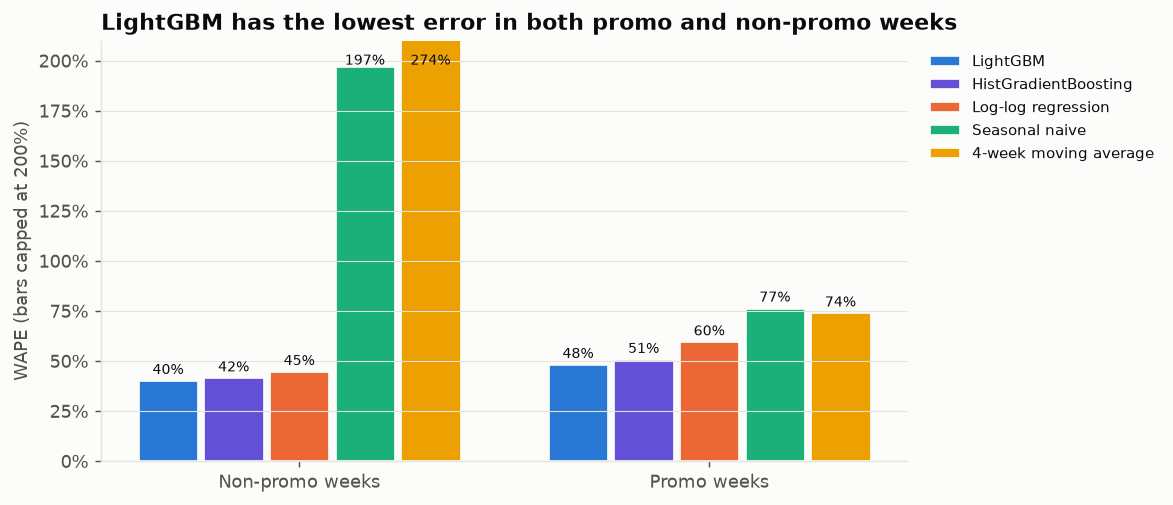

In [4]:
Image(filename=str(figure("forecast_wape_promo_split.png")))

**So what:** LightGBM has the lowest error overall and in promotion weeks, ahead of the second
tree model (HistGradientBoosting) and the regression. Naive baselines are
useless here because volume swings roughly 5-15x between promoted and normal weeks; the log-log regression
is a solid baseline in normal weeks but loses accuracy in promo weeks, where LightGBM's
interactions between discount depth, promo type and recent sales help most.

In [5]:
m[m["slice"] == "series"].pivot_table(index="group", columns="model", values="wape").round(3)

model,hist_gbm,lightgbm,moving_avg_4,regression,seasonal_naive
group,,,,,
7Up | 24pk can,0.666,0.711,1.248,0.743,1.145
7Up | 2L,0.465,0.442,0.942,0.391,0.782
Coke | 24pk can,0.644,0.604,1.031,0.993,0.921
Coke | 2L,0.510,0.493,0.808,0.467,0.809
Diet Coke | 24pk can,0.630,0.597,1.026,0.846,0.930
Diet Coke | 2L,0.503,0.491,0.777,0.428,0.778
Diet Pepsi | 24pk can,0.449,0.429,0.996,0.744,1.010
Diet Pepsi | 2L,0.506,0.472,0.919,0.439,0.868
Pepsi | 24pk can,0.495,0.495,1.015,0.905,1.011


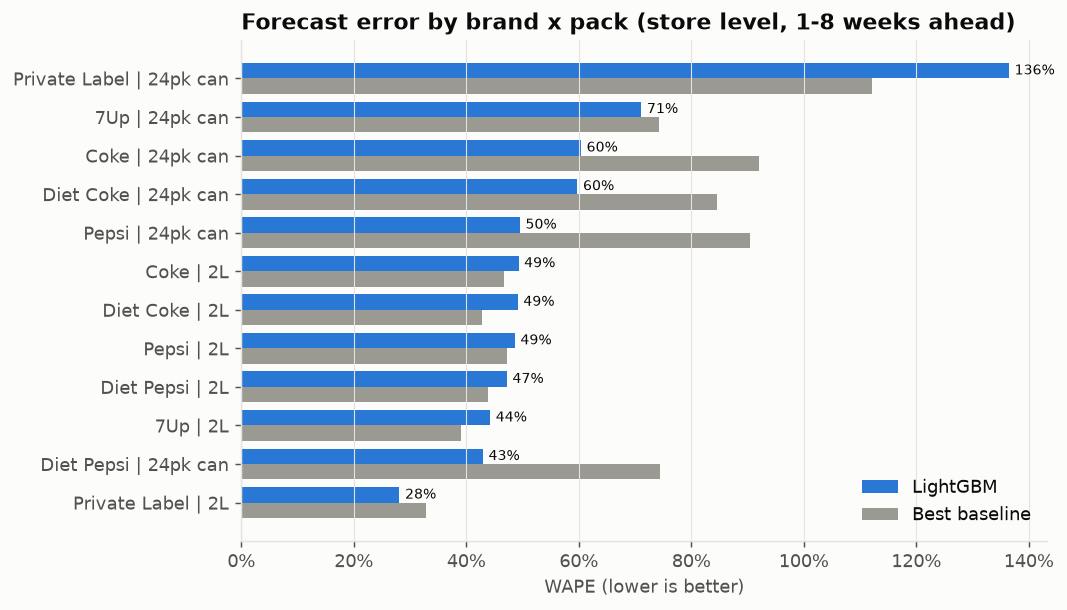

In [6]:
Image(filename=str(figure("forecast_wape_by_series.png")))

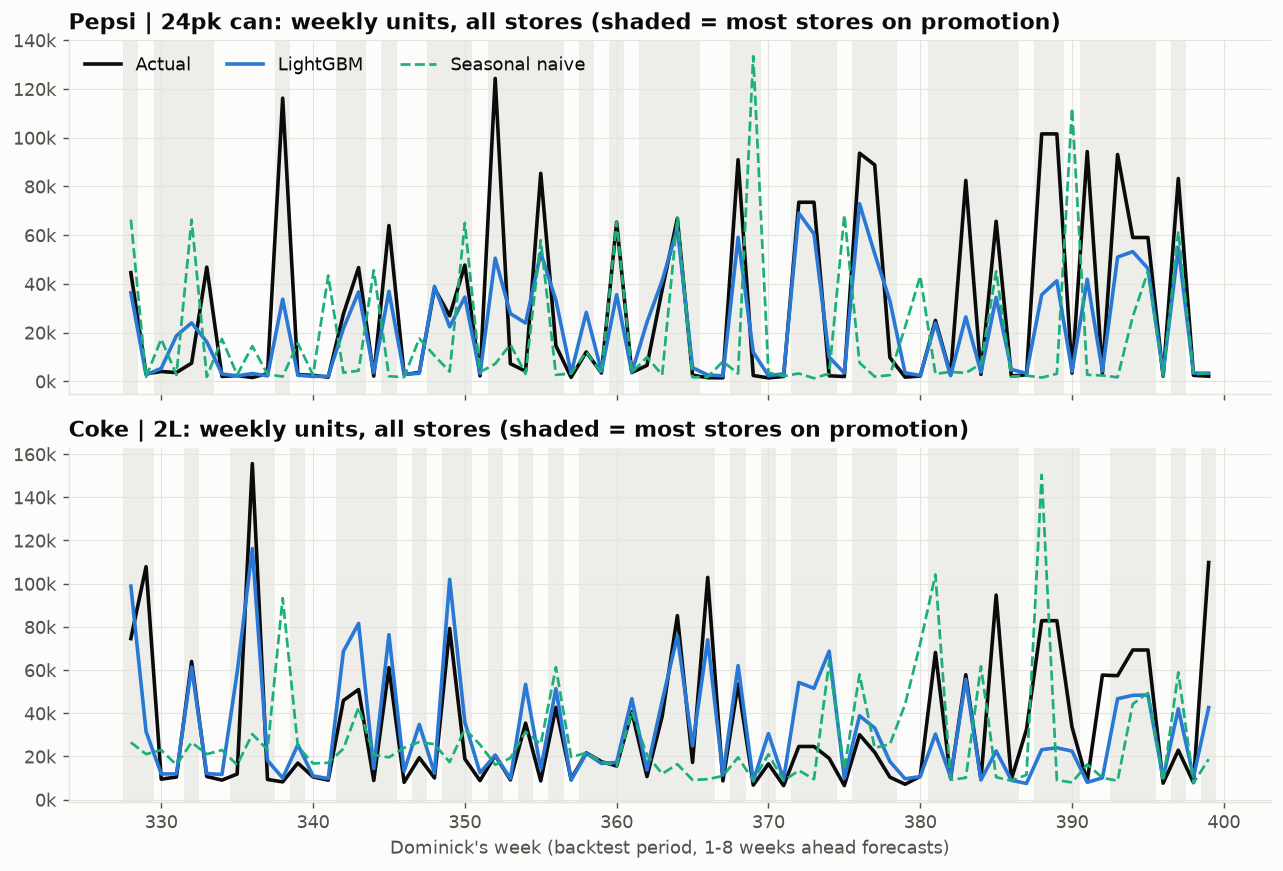

In [7]:
Image(filename=str(figure("forecast_actual_vs_forecast.png")))

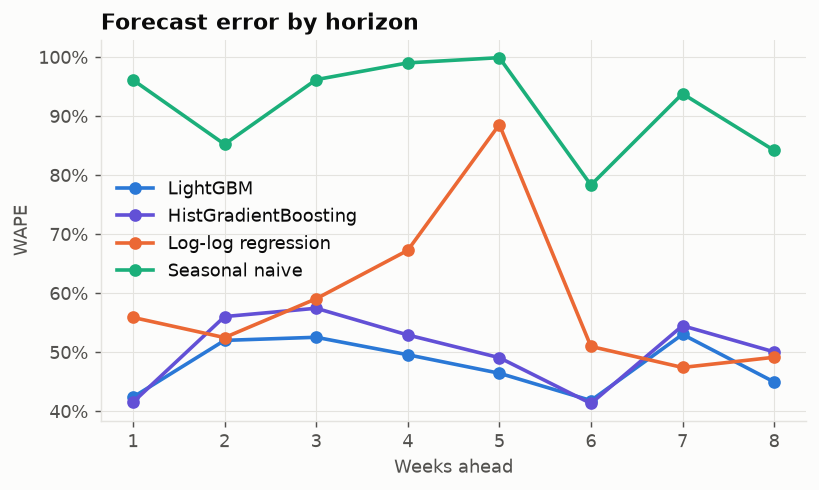

In [8]:
Image(filename=str(figure("forecast_wape_by_horizon.png")))

## 3. Feature ablation -- which inputs matter?

The tuned LightGBM is re-trained on the same folds with one group of features removed at a time.

In [9]:
pd.read_csv(results("ablation.csv")).round(4)

,variant,n_features,wape,wape_promo,wape_non_promo,wape_increase_vs_full
0,full model,45,0.475,0.485,0.405,0.000
1,"without sales history (lags, rolling stats)",36,0.492,0.497,0.448,0.016
2,without price & promotion,33,0.843,0.733,1.670,0.368
3,without calendar & holidays,30,0.474,0.484,0.396,-0.002
4,without store demographics,39,0.482,0.492,0.405,0.006


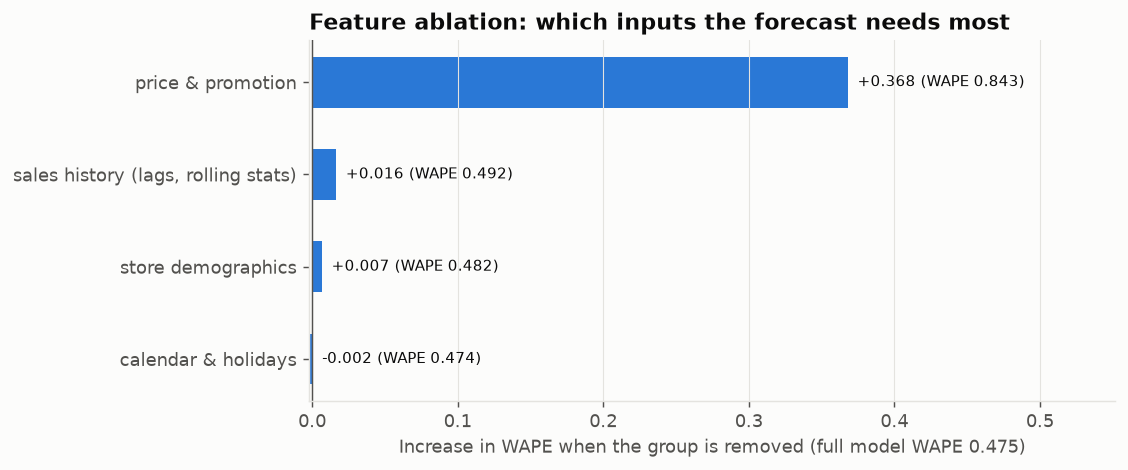

In [10]:
Image(filename=str(figure("forecast_ablation.png")))

**So what:** Removing the price & promotion features hurts by far the most -- without knowing the
promotion plan, the forecast cannot see the spikes coming. Sales history is the second most
important group. Dropping the calendar/holiday features does not hurt (it is even marginally
better): last year's same-week sales and the promotion plan already carry that information.

## 4. What drives the forecast (SHAP)

In [11]:
pd.read_csv(results("forecast_shap_importance.csv")).head(12)

,Unnamed: 0,mean_abs_shap
0,discount depth,0.694
1,13-wk avg sales,0.395
2,own price (log),0.280
3,brand x pack,0.172
4,regular price (log),0.089
5,promo_u,0.077
6,price vs competitors,0.069
7,sin1,0.051
8,bonus-buy flag,0.049
9,price-reduction flag,0.044


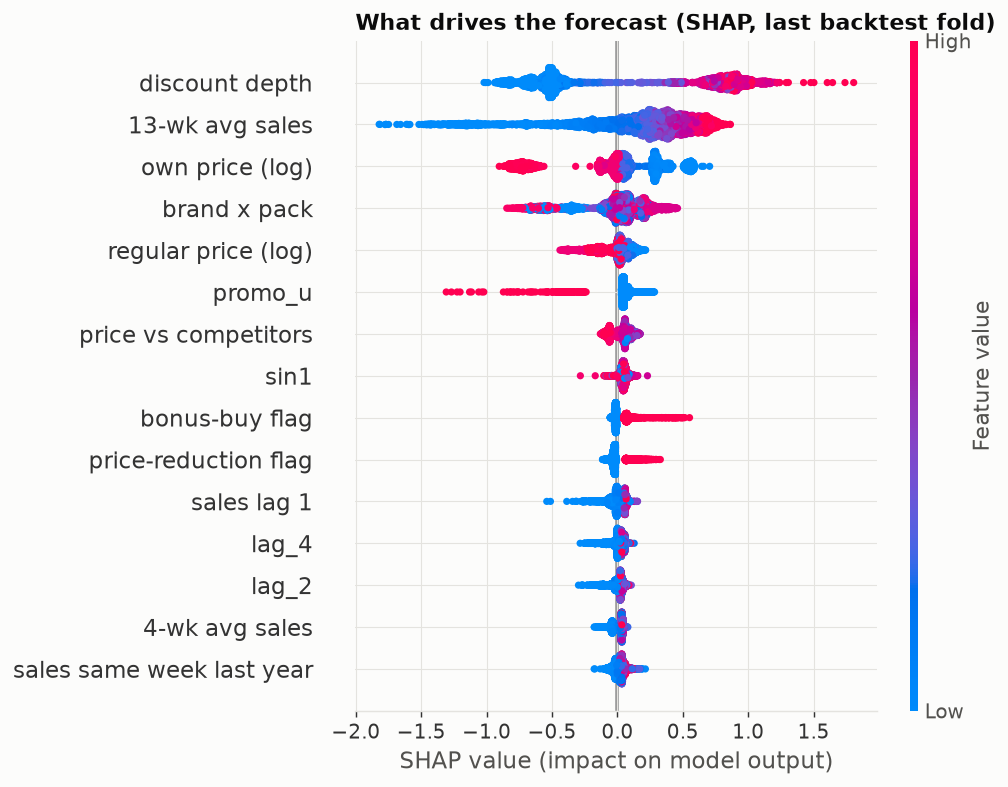

In [12]:
Image(filename=str(figure("forecast_shap_summary.png")))

**So what:** Discount depth is by far the biggest driver of next week's volume, followed by the
store's recent sales level and the price itself. In this category a forecast that does not know
the promotion plan cannot be accurate -- which is why sales and demand-planning teams need to share
the promo calendar.